In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import polars as pl

from src.data.loader import ingest_hillstrom, load_config, stratified_split
from src.models.evaluator import (
    benchmark_models,
    compute_qini_curve,
    placebo_treatment_refutation,
    subset_stability_check,
)
from src.models.uplift import UpliftModelWrapper

cfg = load_config("config/hillstrom.yaml")
processed_path = Path(cfg["processed_path"])
df = pl.read_parquet(processed_path) if processed_path.exists() else ingest_hillstrom(cfg)

train_df, cal_df, test_df = stratified_split(
    df,
    stratify_cols=cfg["split"]["stratify_cols"],
    train_size=cfg["split"]["train_size"],
    cal_size=cfg["split"]["cal_size"],
    test_size=cfg["split"]["test_size"],
    seed=cfg["split"]["random_seed"],
)

feature_cols = cfg["feature_cols"]
treatment_col = cfg["treatment_col"]
target_col = "visit"

X_train = train_df.select(feature_cols)
t_train = train_df[treatment_col]
y_train = train_df[target_col]

X_test = test_df.select(feature_cols)
t_test = test_df[treatment_col]
y_test = test_df[target_col]
print(X_train.shape, X_test.shape)

/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(38400, 8) (12800, 8)


In [2]:
models = {
    name: UpliftModelWrapper(
        estimator_name=name,
        discrete_outcome=True,
        random_state=cfg["split"]["random_seed"],
    )
    for name in UpliftModelWrapper.SUPPORTED_ESTIMATORS
}

results_df = benchmark_models(
    models,
    X_train,
    t_train,
    y_train,
    X_test,
    t_test,
    y_test,
    k_list=(0.1, 0.2, 0.3),
)
results_df

/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)


/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)


/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)


/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)


/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)


/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:103: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:139: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:103: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:139: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/econml/sklearn_extensions/linear_model.py:1946: UserWarning: Co-variance matrix is underdetermined. Inference will be invalid!
  warnings.warn("Co-variance matrix is underdetermined. Inference will be invalid!")
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(ms

/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)


,model,auuc,qini_coeff,uplift_at_10,uplift_at_20,uplift_at_30
0,dr_learner,0.021266,0.036821,0.048269,0.056744,0.067547
1,s_learner,0.019799,0.034803,0.066640,0.073284,0.069251
2,x_learner,0.011365,0.019954,0.082354,0.069194,0.070466
3,naive_propensity,0.010391,0.018702,0.083645,0.062402,0.061564
4,t_learner,0.006698,0.012294,0.040021,0.050898,0.061490
5,causal_forest,0.000024,0.000036,0.050730,0.049642,0.051660
6,random,-0.004299,-0.009192,0.013199,0.046298,0.042114


/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use

/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use

/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)


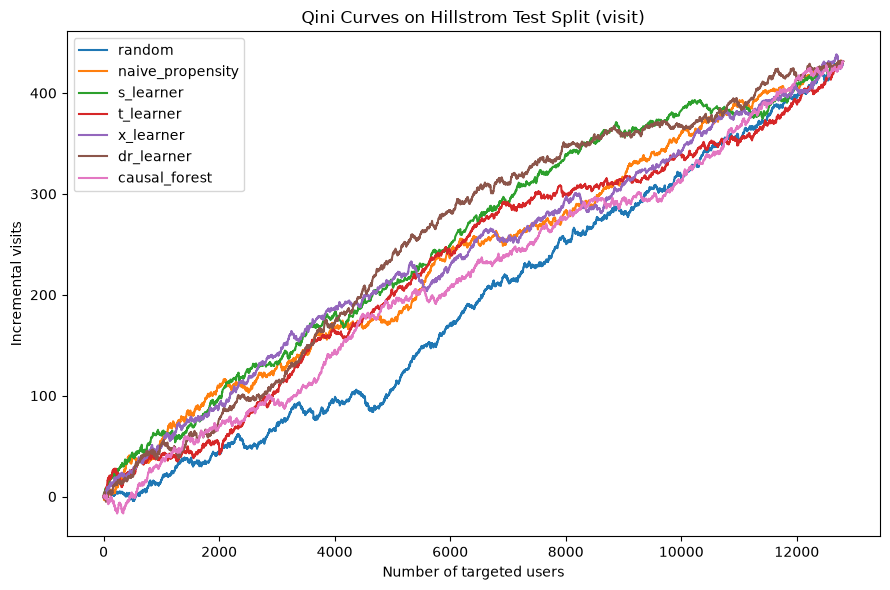

In [3]:
fig, ax = plt.subplots(figsize=(9, 6))
for name, model in models.items():
    pred = model.predict_uplift(X_test)
    qx, qy = compute_qini_curve(y_test, pred, t_test)
    ax.plot(qx, qy, label=name)

ax.set_xlabel("Number of targeted users")
ax.set_ylabel("Incremental visits")
ax.set_title("Qini Curves on Hillstrom Test Split (visit)")
ax.legend()
plt.tight_layout()
plt.show()

In [4]:
cf_lb, cf_ub = models["causal_forest"].predict_interval(X_test)
print("CausalForest mean interval width:", float((cf_ub - cf_lb).mean()))

placebo_df = placebo_treatment_refutation(
    lambda: UpliftModelWrapper("dr_learner", discrete_outcome=True, random_state=42),
    X_train,
    t_train,
    y_train,
    X_test,
    t_test,
    y_test,
    n_repeats=3,
    seed=42,
)
print("Placebo refutation (DR-Learner):")
print(placebo_df)

stability_df = subset_stability_check(
    lambda: UpliftModelWrapper("dr_learner", discrete_outcome=True, random_state=42),
    X_train,
    t_train,
    y_train,
    X_test,
    t_test,
    y_test,
    fraction=0.8,
    n_repeats=3,
    seed=42,
)
print("Subset stability (DR-Learner):")
print(stability_df)

CausalForest mean interval width: 0.2716026484429696


/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:103: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:139: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:103: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:139: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/econml/sklearn_extensions/linear_model.py:1946: UserWarning: Co-variance matrix is underdetermined. Inference will be invalid!
  warnings.warn("Co-variance matrix is underdetermined. Inference will be invalid!")
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(ms

/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:103: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:139: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:103: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:139: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


... (11 outputs left out)

/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:103: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:139: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:103: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:139: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


Subset stability (DR-Learner):
   run      auuc  qini_coeff  uplift_at_20
0    0  0.018406    0.031983      0.043245
1    1  0.020756    0.036463      0.059282
2    2  0.020042    0.034111      0.057323


/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/econml/sklearn_extensions/linear_model.py:1946: UserWarning: Co-variance matrix is underdetermined. Inference will be invalid!
  warnings.warn("Co-variance matrix is underdetermined. Inference will be invalid!")
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(msg, category=FutureWarning)
/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/sklearn/utils/deprecation.py:94: FutureWarning: Function stable_cumsum is deprecated; `sklearn.utils.extmath.stable_cumsum` is deprecated in version 1.8 and will be removed in 1.10. Use `np.cumulative_sum` with the desired dtype directly instead.
  warnings.warn(ms